<a href="https://colab.research.google.com/github/kamo-mphirime/machine-learning-projects/blob/main/adult_income_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo
#model dealing with only numbers
#import everything i needd
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from ucimlrepo import fetch_ucirepo
import sklearn
sklearn.set_config(transform_output="pandas")
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
# Fetch dataset
adult = fetch_ucirepo(id=2)
# Get the full dataframe in one go
df = adult.data.original
# Display the first 5 rows
display(df.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
df = df.dropna()
df['income'] = (df['income'] != '<=50K').astype(int)
display(df['income'].head(10))
y = df.pop('income')
X= df
X = X.drop("fnlwgt", axis=1)



/tmp/ipykernel_2046/3821137609.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['income'] = (df['income'] != '<=50K').astype(int)


,income
0,0
1,0
2,0
3,0
4,0
5,0
6,0
7,1
8,1
9,1


In [ ]:
print(X.columns)

Index(['age', 'workclass', 'education', 'education-num', 'marital-status',
       'occupation', 'relationship', 'race', 'sex', 'capital-gain',
       'capital-loss', 'hours-per-week', 'native-country'],
      dtype='object')


In [ ]:

#when using cat data have to preprocess for missing values
cat_cols= [col for col in X.columns if X[col].dtype=="object"]
print(cat_cols)

['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [ ]:
#here are our cat cols and num cols
cat_cols_data= X[cat_cols].copy()
for col in cat_cols:
    unique_vals = X[col].unique()  # Drop NaN values before finding unique
    print(f"Column '{col}' unique values: {unique_vals}")

Column 'workclass' unique values: ['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov' '?'
 'Self-emp-inc' 'Without-pay' 'Never-worked']
Column 'education' unique values: ['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']
Column 'marital-status' unique values: ['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']
Column 'occupation' unique values: ['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' '?'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']
Column 'relationship' unique values: ['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']
Column 'race' unique values: ['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']
C

In [ ]:
#clean categorical columns
#Impute Based on Contextual Information
def conditional_mode_impute(target_col, group_col,df=cat_cols_data):
    #replace "?" with NA to show cell is empty
    df[target_col] = df[target_col].replace("?", pd.NA)
    df[group_col]  = df[group_col].replace("?", pd.NA)

    # Build lookup from rows where BOTH columns are known
    mode_map = (
        df.dropna(subset=[group_col, target_col])
        .groupby(group_col)[target_col]
        .agg(lambda x: x.mode()[0])
    )

    def fill_row(row):
        if pd.notna(row[target_col]):
            return row[target_col]          # already known, keep it

        if pd.notna(row[group_col]):
            return mode_map.get(row[group_col], pd.NA)  # lookup by group

        return pd.NA                        # both missing → leave for fallback

    df[target_col] = df.apply(fill_row, axis=1)

    # Final fallback: if STILL missing (both were unknown), use global mode
    global_mode = df[target_col].mode()[0]
    df[target_col] = df[target_col].fillna(global_mode)

    return df




In [ ]:
# Step 1: workclass and occupation fix each other
df = conditional_mode_impute( target_col="workclass",group_col="occupation")
df = conditional_mode_impute( target_col="occupation",group_col="workclass")

# Step 2: native-country uses race as context
df = conditional_mode_impute( target_col="native-country", group_col="race")
print(((cat_cols_data) == '?').sum())

workclass         0
education         0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
native-country    0
dtype: int64


In [ ]:
num_cols= [col for col in X.columns if X[col].dtype=="int64"]

education_order = [
    'Preschool', '1st-4th', '5th-6th', '7th-8th',
    '9th', '10th', '11th', '12th', 'HS-grad',
    'Some-college', 'Assoc-voc', 'Assoc-acdm',
    'Bachelors', 'Masters', 'Prof-school', 'Doctorate'
]
ordinal_cols = ['education']
binary_cols = ['sex']
onehot_cols = [
    'workclass', 'marital-status', 'occupation',
    'relationship', 'race', 'native-country']




##################preprocessing all data, define pipelines###############
#Numerical pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

#ordinal pipelind
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[education_order]))
                             ])

#odridal encoder for binary data
binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())  # Male/Female → 0/1 automatically
                           ])
#onehot_pipeline
onehot_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
                            ])
#preprocessor for all columns
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('bin', binary_pipeline, binary_cols),
    ('onehot', onehot_pipeline, onehot_cols)
])

The `education_order` has been updated to include all missing categories like '12th', 'Preschool', and '1st-4th', ensuring the `OrdinalEncoder` can correctly process all education levels in the dataset.

In [ ]:

#models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, random_state=42, verbosity=0, early_stopping_rounds=5),
    'SVM': SVC(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=50)
}

In [ ]:
def create_pipeline(classifier):
    return Pipeline([
        ('preprocessing', preprocessor), # Your ColumnTransformer
        ('classifier', classifier)       # The model being tested
    ])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:

results= {}

for name, model in models.items():
    # Train model
    pipeline = create_pipeline(model)
    if name == 'XGBoost':
        # 1. Grab the preprocessor out of the pipeline
        prep = pipeline.named_steps['preprocessing']

        # 2. Pre-process the data for the eval_set
        # This runs all your mini-pipelines (Ordinal, Binary, OneHot)
        X_train_prepped = prep.fit_transform(X_train)
        X_test_prepped = prep.transform(X_test)

        # 3. Fit the raw XGBoost model using the prepped data
        model.fit(
            X_train_prepped, y_train,
            eval_set=[(X_test_prepped, y_test)],
            verbose=False )
        # 4. STEP C: Sync the trained preprocessor back to the pipeline
        pipeline.named_steps['preprocessing'] = prep
    else:

        pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }
    """
    print(f"\n{name}:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-Score:  {f1:.4f}")"""

print("done!")


done!


In [ ]:
df_results = pd.DataFrame(results).T
print(df_results)

                     Accuracy  Precision    Recall  F1-Score
Logistic Regression  0.659423   0.657681  0.615084  0.635669
Decision Tree        0.600105   0.591709  0.555314  0.572934
Random Forest        0.629921   0.631412  0.561834  0.594595
XGBoost              0.678425   0.717477  0.551402  0.623571
SVM                  0.654803   0.664413  0.576614  0.617407
KNN                  0.656903   0.690483  0.525103  0.596543


<Figure size 1200x600 with 0 Axes>

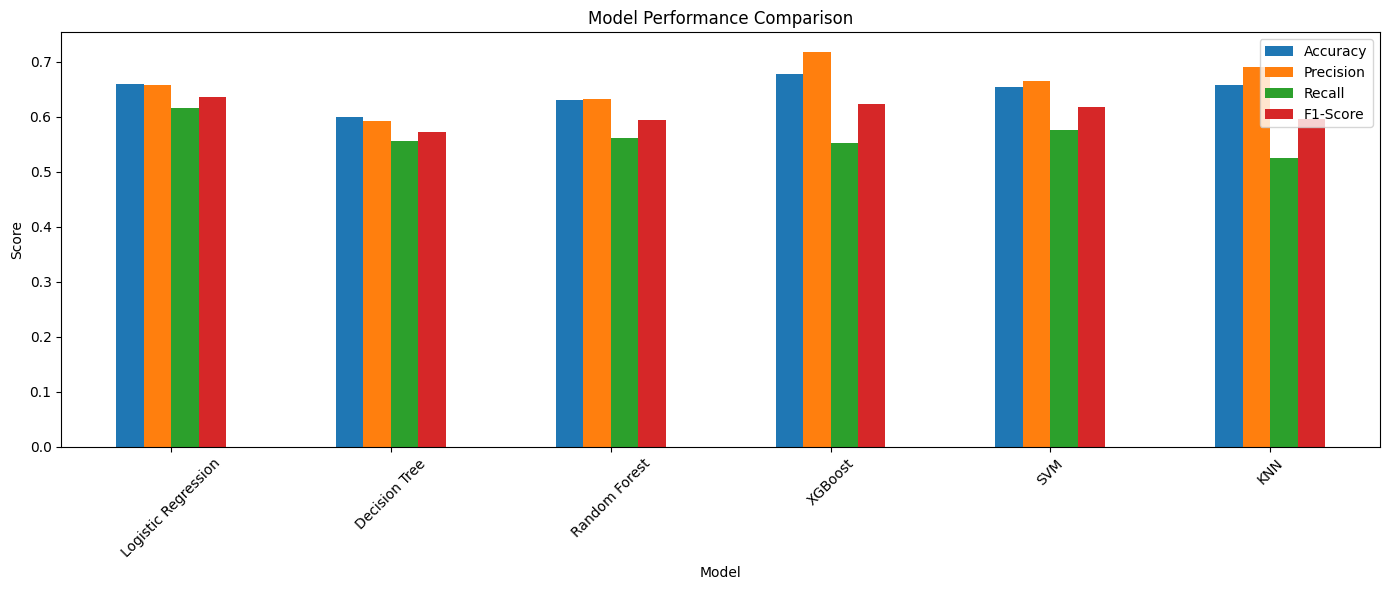


BEST MODEL: XGBoost

Confusion Matrix:
[[3925  999]
 [2064 2537]]

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.80      0.72      4924
           1       0.72      0.55      0.62      4601

    accuracy                           0.68      9525
   macro avg       0.69      0.67      0.67      9525
weighted avg       0.69      0.68      0.67      9525



In [ ]:
# ============ 8. VISUALIZE RESULTS ============
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
df_results.plot(kind='bar', figsize=(14, 6))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=45)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

# ============ 9. BEST MODEL DETAILS ============
best_model_name = df_results['Accuracy'].idxmax()
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test_prepped)

print(f"\n{'='*70}")
print(f"BEST MODEL: {best_model_name}")
print(f"{'='*70}")
print(f"\nConfusion Matrix:\n{confusion_matrix(y_test, y_pred_best)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred_best)}")